# 150. Evaluate Reverse Polish Notation
**Difficulty:** 🟡 Medium · **Topic:** Stack · **Pattern:** [Stack Simulation](README.md) · **LeetCode:** https://leetcode.com/problems/evaluate-reverse-polish-notation/

## 💡 Concepts

**Core concept(s):** a **stack of operands**. Numbers wait on the stack; each operator pops the two most recent numbers, combines them, and pushes the result back.

**Why it applies here:**
- In Reverse Polish Notation (RPN) an operator always applies to the **two most recent values that are still unused**.
- "Most recent first" is exactly what a stack hands back.
- The result of an operator is itself a value that a later operator will use, so it goes back on the stack.

**Key intuition:**
- Read tokens left to right. Number → push. Operator → pop `b`, pop `a`, push `a op b`.
- The **first** pop is the **right** operand. For `-` and `/` the order matters: `"4" "2" "-"` means `4 - 2`.
- At the end exactly one value is left: the answer.

---

### 📚 What is a Stack?
- A **stack** is a "last in, first out" pile, like a stack of plates.
- You **push** onto the top and **pop** from the top.
- **Complexity:** push / pop / peek are **O(1)**.
- **In Python:** a plain `list`: `append(x)` pushes, `pop()` removes and returns the top.

### 📚 What is Reverse Polish Notation (postfix)?
- Normal (infix) notation puts the operator **between** its operands: `(2 + 1) * 3`.
- **Postfix / RPN** puts it **after** them: `2 1 + 3 *`.
- No parentheses and no precedence rules are needed: the order of the tokens already says what to compute first.
- Calculators and stack-based virtual machines (the Python and Java bytecode interpreters) evaluate expressions this way.

### 📚 Truncating division toward zero
- The problem says division **truncates toward zero**: `7 / -2 = -3`, `-7 / 2 = -3`.
- Python's `//` **floors** instead (rounds toward minus infinity): `7 // -2 == -4`. Using it gives wrong answers when the signs differ.
- `int(a / b)` divides as a float, then `int` drops the fraction, which rounds toward zero. With 32-bit operands the float is exact enough for this to be correct.

---

**Prerequisite knowledge:**
- Using a `list` as a stack.
- `operator.add` / `sub` / `mul`: the `+`, `-`, `*` operators as plain functions.

## 📝 Problem

You get an arithmetic expression in **Reverse Polish Notation** as a list of string tokens. Each token is an integer or one of `+`, `-`, `*`, `/`. Evaluate it and return the integer result.

**Example 1**
```
tokens = ["2", "1", "+", "3", "*"]   ->  9      ((2 + 1) * 3)
```
**Example 2**
```
tokens = ["4", "13", "5", "/", "+"]  ->  6      (4 + (13 / 5)) = 4 + 2
```
**Example 3**
```
tokens = ["10","6","9","3","+","-11","*","/","*","17","+","5","+"]  ->  22
```

**Constraints:** `1 <= len(tokens) <= 10^4`; the expression is always valid; no division by zero; every intermediate result fits in a 32-bit integer; division truncates toward zero.

> Two approaches: repeatedly find the first operator and collapse it with its two operands (`O(n²)`), then the stack of operands (`O(n)`).

In [1]:
from typing import List
import operator

# One table maps each operator token to a function of two ints.
# Division truncates toward zero: int(a / b). Python's a // b floors (-7 // 2 == -4), which is wrong here.
OPS = {
    "+": operator.add,
    "-": operator.sub,
    "*": operator.mul,
    "/": lambda a, b: int(a / b),
}

### Approach 1 — Brute Force: collapse the first operator, repeat

**Idea:**
1. Find the **first** operator in the token list. Because no operator comes before it, the two tokens right before it are plain numbers: its operands.
2. Replace those three tokens with the single result.
3. Repeat until one token is left.

**Time complexity:** `O(n²)` — each round scans from the start to find the first operator and rebuilds the list (both `O(n)`), and there are up to `n/2` rounds.

**Space complexity:** `O(n)` for the working copy of the tokens.

In [2]:
def eval_rpn_brute(tokens: List[str]) -> int:
    toks = list(tokens)                                    # work on a copy, never mutate the input
    while len(toks) > 1:
        i = next(k for k, t in enumerate(toks) if t in OPS)   # O(n) scan for the first operator
        a, b = int(toks[i - 2]), int(toks[i - 1])          # its two operands sit right before it
        toks[i - 2:i + 1] = [str(OPS[toks[i]](a, b))]      # O(n): shift the tail left by 2
    return int(toks[0])

### Approach 2 — Stack of operands (optimal · pattern template)

**Idea:** the [Stack Simulation](README.md) template: push the items that wait, pop when a token resolves them.
1. Scan tokens left to right.
2. A number waits for an operator: push it.
3. An operator resolves the two most recent numbers: pop `b` (right operand), pop `a` (left operand), push `OPS[t](a, b)`. The result waits for a later operator like any other number.
4. When the scan ends, the single value on the stack is the answer.

**Time complexity:** `O(n)` — every token is pushed or triggers two pops and one push, all `O(1)`.

**Space complexity:** `O(n)` — the stack can hold about half the tokens when all numbers come first.

In [3]:
def eval_rpn_stack(tokens: List[str]) -> int:
    stack = []                             # operands waiting for an operator
    for t in tokens:
        if t in OPS:                       # operator: resolve the two most recent operands
            b = stack.pop()                # first pop = RIGHT operand
            a = stack.pop()                # second pop = LEFT operand
            stack.append(OPS[t](a, b))     # the result waits like any other operand
        else:
            stack.append(int(t))           # number: push and wait
    return stack[0]                        # a valid expression leaves exactly one value

In [4]:
# Correctness check
import random

tests = [
    (["2", "1", "+", "3", "*"], 9),                                              # LeetCode example 1
    (["4", "13", "5", "/", "+"], 6),                                             # LeetCode example 2: 13 / 5 = 2
    (["10", "6", "9", "3", "+", "-11", "*", "/", "*", "17", "+", "5", "+"], 22), # LeetCode example 3
    (["6", "-132", "/"], 0),          # truncate toward zero: -0.045 -> 0 (floor // would give -1)
    (["7", "-2", "/"], -3),           # -3.5 -> -3 (floor would give -4)
    (["4", "2", "-"], 2),             # operand order: 4 - 2, not 2 - 4
    (["42"], 42),                     # a single number
]
for tokens, exp in tests:
    a, b = eval_rpn_brute(tokens), eval_rpn_stack(tokens)
    print(f"{str(tokens):70} -> {b}")
    assert a == b == exp, f"mismatch on {tokens}: brute={a} stack={b} expected={exp}"

# Randomised cross-check: random valid expressions (no division by zero), both approaches must agree
rng = random.Random(150)
for _ in range(300):
    tokens, depth = [], 0
    for _ in range(rng.randint(1, 30)):
        if depth >= 2 and rng.random() < 0.5:
            tokens.append(rng.choice("+-*")); depth -= 1
        else:
            tokens.append(str(rng.randint(-9, 9))); depth += 1
    while depth > 1:
        tokens.append(rng.choice("+-")); depth -= 1
    assert eval_rpn_brute(tokens) == eval_rpn_stack(tokens), tokens
print("300 random expressions: both approaches agree")

print("\nAll tests passed")

['2', '1', '+', '3', '*']                                              -> 9
['4', '13', '5', '/', '+']                                             -> 6
['10', '6', '9', '3', '+', '-11', '*', '/', '*', '17', '+', '5', '+']  -> 22
['6', '-132', '/']                                                     -> 0
['7', '-2', '/']                                                       -> -3
['4', '2', '-']                                                        -> 2
['42']                                                                 -> 42
300 random expressions: both approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | ≈ **2×** (slightly more) |
| `O(n²)`       | ≈ **4×** |

The worst case for the brute force puts **all numbers first, then all operators** (`"1" "1" ... "1" "*" "/" "*" ...`): every round scans past the remaining numbers to find the first operator and shifts the list, so it should show ≈4×. The stack stays ≈2×. All values are `1` and the operators alternate `*` and `/`, so every intermediate result is `1` and the arithmetic stays `O(1)`.


collapse first operator O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       2.25 |           n/a
     2000 |       8.78 |         3.91x
     4000 |      35.81 |         4.08x
     8000 |     147.17 |         4.11x

stack of operands O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       0.07 |           n/a
     2000 |       0.11 |         1.55x
     4000 |       0.21 |         1.89x
     8000 |       0.42 |         1.94x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


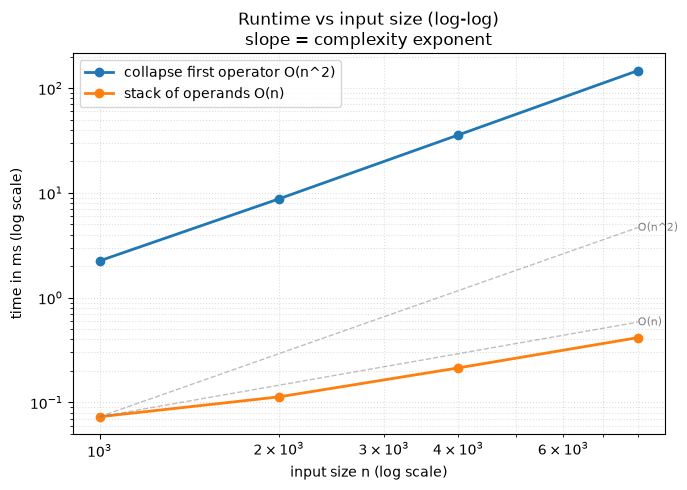

{'collapse first operator O(n^2)': [2.247709082439542,
  8.784750010818243,
  35.809417022392154,
  147.1715000225231],
 'stack of operands O(n)': [0.0730419997125864,
  0.11304207146167755,
  0.2137920819222927,
  0.415584072470665]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    k = n // 2
    tokens = ["1"] * (k + 1) + ["*" if j % 2 else "/" for j in range(k)]   # 2k+1 tokens, value stays 1
    return (tokens,)

solutions = {
    "collapse first operator O(n^2)": eval_rpn_brute,
    "stack of operands O(n)": eval_rpn_stack,
}
sizes = [1000, 2000, 4000, 8000]

benchmark(solutions, make_worst_case, sizes, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Stack Simulation](README.md) — numbers are pushed to wait; each operator pops the two most recent, combines them, and pushes the result back for a later operator.
- **Postfix evaluation = stack of operands:** "apply to the most recent unused values" is last-in, first-out, so a stack replaces repeated rescans of the token list.
- **Signal:** "Reverse Polish / postfix notation", "evaluate an expression", "each operator applies to the previous two values", "undo the last" style processing.
- **Related problems:** Basic Calculator (I/II/III), Valid Parentheses, Asteroid Collision, Decode String.
- **Common pitfalls:**
  1. Swapping the operands: the **first** pop is the **right** operand (`a - b`, `a / b`).
  2. Using `//` for division: it floors, so `7 // -2 == -4`, but the problem wants `-3`. Use `int(a / b)`.
  3. Pushing the token string instead of `int(t)`, then concatenating strings with `+`.
  4. Checking `t.isdigit()` to detect numbers: it is `False` for negative numbers like `"-11"`. Check for the operator instead.